## 0. Підготовка середовища

Встановив необхідні бібліотеки, задав `seed=42` для відтворюваності результатів і створив папки для моделей та логів.

In [1]:
import sys
import subprocess

packages = [
    "transformers[sentencepiece]>=4.52.4,<5",
    "datasets>=3.0,<5",
    "tokenizers>=0.21,<0.24",
    "evaluate>=0.4,<1",
    "gradio>=4.44,<7",
    "tensorboard>=2.16",
    "scikit-learn>=1.2",
    "accelerate>=1.0",
    "pyarrow",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


0

In [2]:
import gc
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd() / "lab3"
MODELS_DIR = ROOT / "models"
RUNS_DIR = ROOT / "runs"
TOKENIZERS_DIR = ROOT / "tokenizers"
for folder in (MODELS_DIR, RUNS_DIR, TOKENIZERS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = ROOT / "results.csv"
RESULTS = []


## Завдання 0. Аналіз демо-ноутбука

### 0.1. Відповіді на питання

**1. Чому в `train_from_iterator` передаю список документів, а не один рядок?** Метод працює з ітератором текстів. Якщо передати рядок як ітератор, він розіб'ється на окремі символи. Список документів дозволяє поступово обробляти дані та не тримати весь об'єднаний текст в одному великому рядку.

**2. Які етапи токенізації?** Спочатку текст нормалізується, потім розбивається на початкові фрагменти. Далі алгоритм BPE, WordPiece або Unigram формує токени, яким відповідають числові ID. За потреби додаються спеціальні токени.

**3. Для чого потрібні `<unk>` та `<eos>`?** `<unk>` позначає невідомий токен, а `<eos>` - кінець документа або послідовності. Кожен має окремий ID у словнику.

**4. Що буде, якщо зменшити `VOCAB_SIZE`?** Очікую, що слова частіше ділитимуться на менші частини, тому кількість токенів зросте. При незмінному `CONTEXT_LEN` модель бачитиме менше початкового тексту. Порівняння BPE зі словниками 16000 і 5000 виконую в завданні 1.

**5. Чому додаю `<eos>` між документами?** Щоб модель відрізняла кінець одного резюме від початку іншого та не сприймала їх як один суцільний текст.

**6. Що містять `train_data` і `val_data`?** Це одновимірні тензори `torch.long` з ID токенів. Для навчання беру `x` - вхідну послідовність, і `y` - ту саму послідовність зі зсувом на один токен.

**7. Як перевірив правильність батчу?** Використав `assert torch.equal(x[:, 1:], y[:, :-1])`. Перевірка є в завданні 3.2.

**8. Для чого причинна маска в attention?** Вона не дозволяє поточній позиції бачити майбутні токени. Без неї модель могла б отримувати інформацію про правильну відповідь під час навчання, хоча під час генерації майбутніх токенів ще немає.

**9. Коли збігаються найкращий і останній чекпоінти?** Коли мінімальний `val_loss` отримано на останній оцінці. Якщо найменша помилка була раніше, найкращий чекпоінт відрізнятиметься від останнього. Перевіряю це після навчання двох моделей.

**10. Що зміниться, якщо зменшити `EVAL_INTERVAL` з 250 до 50?** Оцінювання відбуватиметься частіше, тому на графіку буде більше точок. Водночас збільшиться час виконання через додаткові перевірки. Самі значення loss не обов'язково стануть плавнішими.

**11. Як працює `temperature`?** Перед `softmax` логіти діляться на температуру. При значенні менше 1 модель частіше обирає найімовірніші токени, а при значенні більше 1 відповіді стають різноманітнішими.

**12. Що робить `top_p`?** Залишає найімовірніші токени, сумарна ймовірність яких досягає заданого порога. Наступний токен вибирається з цієї групи.

**13. Що змінює `enable_thinking`?** При `True` Qwen3 може генерувати проміжні міркування, а при `False` переходить до відповіді без такого блоку. Порівнюю обидва режими у завданні 4.7.

## Завдання 1. Завантаження датасету

Використав [датасет із профілями IT-кандидатів](https://huggingface.co/datasets/lang-uk/recruitment-dataset-candidate-profiles-ukrainian). Основна колонка - `CV`. Набір містить спліт `train`, тому поділ на навчальні та валідаційні документи зробив сам.

In [3]:
from datasets import load_dataset

DATASET_ID = "lang-uk/recruitment-dataset-candidate-profiles-ukrainian"
raw_ds = load_dataset(DATASET_ID, split="train")
assert "CV" in raw_ds.column_names, "Колонка CV не знайдена. Перевірте датасет."

if "CV_lang" in raw_ds.column_names:
    raw_ds = raw_ds.filter(lambda r: str(r.get("CV_lang", "")).lower() == "uk")

cv_docs = [str(s).strip() for s in raw_ds["CV"] if isinstance(s, str) and len(s.strip()) >= 40]
cv_docs = list(dict.fromkeys(cv_docs))
assert len(cv_docs) >= 200, "Недостатньо текстів для тренування."
corpus_text = "\n\n".join(cv_docs)

stats = {
    "Документів": len(cv_docs),
    "Символів": len(corpus_text),
    "Слів": len(corpus_text.split()),
    "Унікальних слів (нижній регістр)": len(set(w.lower() for w in corpus_text.split())),
}
display(pd.DataFrame(stats.items(), columns=["Показник", "Значення"]))
display(pd.DataFrame({"Приклад CV": [cv_docs[0][:350]]}))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/32.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/24230 [00:00<?, ? examples/s]

Filter:   0%|          | 0/24230 [00:00<?, ? examples/s]

,Показник,Значення
0,Документів,24208
1,Символів,17891086
2,Слів,2411839
3,Унікальних слів (нижній регістр),229453


,Приклад CV
0,"Розробник 1с/BAS, всі українські конфігурації,..."


In [4]:
from sklearn.model_selection import train_test_split
train_docs, val_docs = train_test_split(cv_docs, test_size=0.10, random_state=SEED, shuffle=True)
assert set(train_docs).isdisjoint(set(val_docs))
display(pd.DataFrame({"Частина": ["train", "val"], "Документів": [len(train_docs), len(val_docs)]}))


,Частина,Документів
0,train,21787
1,val,2421


### 1.1. Порівняння BPE з різним розміром словника

Повторив експеримент із демо на однаковій вибірці CV. Навчив BPE зі словниками 16000 і 5000 токенів та порівняв довжину закодованих текстів і частку невідомих токенів.

In [5]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers

SPECIAL_TOKENS = ["<unk>", "<eos>"]

def train_byte_bpe(documents, vocab_size):
    t = Tokenizer(models.BPE(unk_token="<unk>"))
    t.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    t.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size, min_frequency=2,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        special_tokens=SPECIAL_TOKENS,
    )
    t.train_from_iterator(documents, trainer=trainer, length=len(documents))
    return t

EXPERIMENT_TRAIN = train_docs[:2500]
EXPERIMENT_TEST = val_docs[:300]
bpe_16000 = train_byte_bpe(EXPERIMENT_TRAIN, 16000)
bpe_5000 = train_byte_bpe(EXPERIMENT_TRAIN, 5000)

def tokenizer_statistics(tokenizer, texts):
    encoded = tokenizer.encode_batch(texts)
    total = sum(len(e.ids) for e in encoded)
    unk_id = tokenizer.token_to_id("<unk>")
    unknown = sum(sum(x == unk_id for x in e.ids) for e in encoded)
    return {
        "Розмір словника": tokenizer.get_vocab_size(),
        "Середня кількість токенів / CV": round(total / len(encoded), 2),
        "Частка <unk>, %": round(unknown / max(total, 1) * 100, 4),
    }

bpe_compare = pd.DataFrame([
    {"BPE": "16000", **tokenizer_statistics(bpe_16000, EXPERIMENT_TEST)},
    {"BPE": "5000", **tokenizer_statistics(bpe_5000, EXPERIMENT_TEST)},
])
display(bpe_compare)


,BPE,Розмір словника,Середня кількість токенів / CV,"Частка <unk>, %"
0,16000,16000,203.03,0.0
1,5000,5000,251.31,0.0


## Завдання 2. Токенізатори BPE, WordPiece та Unigram

### 2.1. Навчання токенізатора на основі готового

Завантажив токенізатор Qwen2.5 і перенавчив його на частині українських CV за допомогою `train_new_from_iterator`.


In [6]:
from transformers import AutoTokenizer

BASE_TOKENIZER = "Qwen/Qwen2.5-0.5B-Instruct"
base_tok = AutoTokenizer.from_pretrained(BASE_TOKENIZER, use_fast=True)
new_tok = base_tok.train_new_from_iterator(train_docs[:2500], vocab_size=4000)
examples = ["Досвід розробки на Python", "Створюю інтерфейси для мобільних застосунків"]
display(pd.DataFrame({
    "Текст": examples,
    "Токени": [new_tok.tokenize(example) for example in examples],
}))
new_tok.save_pretrained(str(TOKENIZERS_DIR / "qwen_retrained"))


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

,Текст,Токени
0,Досвід розробки на Python,"[ÐĶÐ¾ÑģÐ²ÑĸÐ´, ĠÑĢÐ¾Ð·ÑĢÐ¾Ð±ÐºÐ¸, ĠÐ½Ð°, ĠPython]"
1,Створюю інтерфейси для мобільних застосунків,"[Ð¡ÑĤÐ²Ð¾ÑĢ, ÑİÑİ, ĠÑĸÐ½ÑĤÐµÑĢÑĦ, ÐµÐ¹ÑģÐ¸, ĠÐ..."


('/content/lab3/tokenizers/qwen_retrained/tokenizer_config.json',
 '/content/lab3/tokenizers/qwen_retrained/special_tokens_map.json',
 '/content/lab3/tokenizers/qwen_retrained/chat_template.jinja',
 '/content/lab3/tokenizers/qwen_retrained/vocab.json',
 '/content/lab3/tokenizers/qwen_retrained/merges.txt',
 '/content/lab3/tokenizers/qwen_retrained/added_tokens.json',
 '/content/lab3/tokenizers/qwen_retrained/tokenizer.json')

### 2.2. Навчання BPE, WordPiece та Unigram

Навчив три токенізатори на одному корпусі. Для всіх використав нормалізацію `NFKC`, розбиття `Whitespace` і цільовий розмір словника 500 токенів.

In [7]:
COMPARE_VOCAB = 500
COMPARE_TEXTS = train_docs[:2000]

def build_tokenizer(kind, vocab_size=COMPARE_VOCAB):
    if kind == "BPE":
        tok = Tokenizer(models.BPE(unk_token="<unk>"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS)
    elif kind == "WordPiece":
        tok = Tokenizer(models.WordPiece(unk_token="<unk>"))
        trainer = trainers.WordPieceTrainer(
            vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS,
            continuing_subword_prefix="##",
        )
        tok.decoder = decoders.WordPiece(prefix="##")
    elif kind == "Unigram":
        tok = Tokenizer(models.Unigram())
        trainer = trainers.UnigramTrainer(
            vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS, unk_token="<unk>"
        )
    else:
        raise ValueError(kind)
    tok.normalizer = normalizers.NFKC()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(COMPARE_TEXTS, trainer=trainer, length=len(COMPARE_TEXTS))
    return tok

tokenizers_three = {name: build_tokenizer(name) for name in ("BPE", "WordPiece", "Unigram")}
for name, tok in tokenizers_three.items():
    tok.save(str(TOKENIZERS_DIR / f"{name.lower()}.json"))


### 2.3. Порівняння результатів

Перевірив кількість токенів на одному тексті та двох словах: `розробка` і `мікросервісами`. Також порівнюю частку `<unk>` і саме розбиття тексту на токени.

In [8]:
SAMPLE_TEXT = "Маю досвід розробки вебзастосунків на Python і створення інтерфейсів для користувачів."
WORDS = ["розробка", "мікросервісами"]
rows = []
for name, tok in tokenizers_three.items():
    enc = tok.encode(SAMPLE_TEXT)
    rows.append({
        "Алгоритм": name,
        "Словник": tok.get_vocab_size(),
        "Токенів у фрагменті": len(enc.ids),
        f"'{WORDS[0]}'": len(tok.encode(WORDS[0]).ids),
        f"'{WORDS[1]}'": len(tok.encode(WORDS[1]).ids),
        "<unk> у фрагменті": sum(i == tok.token_to_id("<unk>") for i in enc.ids),
    })
comparison_tok = pd.DataFrame(rows).sort_values("Токенів у фрагменті")
display(comparison_tok)
display(pd.DataFrame([
    {"Алгоритм": name, "Токени": tok.encode(SAMPLE_TEXT).tokens}
    for name, tok in tokenizers_three.items()
]))


,Алгоритм,Словник,Токенів у фрагменті,'розробка','мікросервісами',<unk> у фрагменті
2,Unigram,500,29,2,6,0
0,BPE,500,30,2,7,0
1,WordPiece,500,42,2,10,0


,Алгоритм,Токени
0,BPE,"[Маю, досвід, розроб, ки, ве, б, за, сто, су, ..."
1,WordPiece,"[М, ##аю, досвід, розроб, ##ки, в, ##е, ##б, #..."
2,Unigram,"[Маю, досвід, розробк, и, веб, за, ст, о, с, у..."


## Завдання 3. Навчання mini-GPT

### 3.1. Підготовка токенів

Навчив ByteLevel BPE на навчальних CV. Додав `<eos>` після кожного документа та перетворив тексти на послідовності ID токенів.

In [9]:
GPT_VOCAB = 6000
ENCODE_BATCH = 400

gpt_tokenizer = train_byte_bpe(train_docs, GPT_VOCAB)
gpt_tokenizer.save(str(TOKENIZERS_DIR / "minigpt_bpe.json"))
EOS_ID = gpt_tokenizer.token_to_id("<eos>")
VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

def encode_document_stream(documents):
    chunks = []
    for start in range(0, len(documents), ENCODE_BATCH):
        batch = gpt_tokenizer.encode_batch(documents[start:start + ENCODE_BATCH])
        for enc in batch:
            chunks.append(np.asarray(enc.ids + [EOS_ID], dtype=np.int32))
    return torch.from_numpy(np.concatenate(chunks).astype(np.int64))

train_data = encode_document_stream(train_docs)
val_data = encode_document_stream(val_docs)
assert len(train_data) > 5000 and len(val_data) > 1000
display(pd.DataFrame({
    "Показник": ["Токени train", "Токени val", "Розмір словника", "Частка <unk> у val"],
    "Значення": [len(train_data), len(val_data), VOCAB_SIZE,
                 (val_data == gpt_tokenizer.token_to_id("<unk>")).float().mean().item()],
}))

del corpus_text, raw_ds
gc.collect()


,Показник,Значення
0,Токени train,4670344.0
1,Токени val,518312.0
2,Розмір словника,6000.0
3,Частка <unk> у val,0.0


180

### 3.2. Формування батчів

Підготував випадкові батчі для навчання. Перевірив через `assert`, що цільова послідовність зсунута на один токен відносно вхідної.

In [10]:
def get_batch(split, context_len, batch_size):
    src = train_data if split == "train" else val_data
    if len(src) <= context_len + 1:
        raise ValueError("Недостатня довжина набору токенів")
    ix = torch.randint(0, len(src) - context_len, (batch_size,))
    x = torch.stack([src[int(i):int(i)+context_len] for i in ix])
    y = torch.stack([src[int(i)+1:int(i)+context_len+1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train", 64, 8)
assert xb.shape == yb.shape == (8, 64)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "Зсув цілей не відповідає входам"


### 3.3. Реалізація mini-GPT

Написав класи `AttentionHead`, `MultiHeadAttention`, `TransformerBlock` і `MiniGPT`. Використав причинну маску, щоб модель не бачила наступні токени під час навчання.

In [11]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.q = nn.Linear(embed_dim, head_dim, bias=False)
        self.k = nn.Linear(embed_dim, head_dim, bias=False)
        self.v = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        _, T, _ = x.shape
        q, k, v = self.q(x), self.k(x), self.v(x)
        weights = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        weights = weights.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(weights, dim=-1))
        return weights @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        assert embed_dim % n_heads == 0
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, embed_dim // n_heads, context_len, dropout)
            for _ in range(n_heads)
        ])
        self.proj = nn.Sequential(nn.Linear(embed_dim, embed_dim), nn.Dropout(dropout))

    def forward(self, x):
        return self.proj(torch.cat([h(x) for h in self.heads], dim=-1))

class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim), nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim), nn.Dropout(dropout),
        )
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, n_heads=4, n_layers=2,
                 context_len=64, dropout=0.1):
        super().__init__()
        self.context_len = context_len
        self.token_emb = nn.Embedding(vocab_size, embed_dim)
        self.pos_emb = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout)
            for _ in range(n_layers)
        ])
        self.ln = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, vocab_size)

    def forward(self, ids, targets=None):
        _, T = ids.shape
        assert T <= self.context_len
        x = self.token_emb(ids) + self.pos_emb(torch.arange(T, device=ids.device))
        logits = self.head(self.ln(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.shape[-1]), targets.reshape(-1)
        )
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, new_tokens=60, temperature=0.8, top_k=35):
        self.eval()
        for _ in range(new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                k = min(top_k, logits.shape[-1])
                top = torch.topk(logits, k).values[:, -1].unsqueeze(-1)
                logits = logits.masked_fill(logits < top, float("-inf"))
            probs = torch.softmax(logits, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

smoke = MiniGPT(VOCAB_SIZE, n_layers=2).to(device)
with torch.no_grad():
    logits, loss = smoke(xb, yb)
assert logits.shape == (8, 64, VOCAB_SIZE) and torch.isfinite(loss)
del smoke, logits, loss, xb, yb
gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()


### 3.4. Навчання двох варіантів

Навчаю дві моделі з однаковими параметрами, крім кількості Transformer-блоків: у `v1` - 2, у `v2` - 4. Зберігаю найкращі ваги за `val_loss`, історію навчання та TensorBoard-логи.

In [12]:
from torch.utils.tensorboard import SummaryWriter

EMBED_DIM = 128
N_HEADS = 4
CONTEXT_LEN = 64
BATCH_SIZE = 24 if device.type == "cuda" else 8
MAX_ITERS = 500 if device.type == "cuda" else 120
EVAL_INTERVAL = 50
EVAL_ITERS = 8 if device.type == "cuda" else 3
LEARNING_RATE = 3e-4

@torch.no_grad()
def evaluate_model(model, context_len, batch_size, eval_iters):
    model.eval()
    out = {}
    for split in ("train", "val"):
        scores = []
        for _ in range(eval_iters):
            x, y = get_batch(split, context_len, batch_size)
            scores.append(model(x, y)[1].item())
        out[split] = float(np.mean(scores))
    model.train()
    return out

def train_variant(name, n_layers, max_iters=MAX_ITERS, eval_interval=EVAL_INTERVAL,
                  eval_iters=EVAL_ITERS, persist=True):
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model = MiniGPT(
        VOCAB_SIZE, embed_dim=EMBED_DIM, n_heads=N_HEADS,
        n_layers=n_layers, context_len=CONTEXT_LEN, dropout=0.1,
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    writer = SummaryWriter(str(RUNS_DIR / name)) if persist else None
    checkpoint_path = MODELS_DIR / f"minigpt_{name}.pt"
    first_path = MODELS_DIR / f"minigpt_{name}_first.pt"
    best_val, best_iter = float("inf"), None
    history = []
    begin = time.perf_counter()
    for it in range(max_iters):
        model.train()
        x, y = get_batch("train", CONTEXT_LEN, BATCH_SIZE)
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if it % eval_interval == 0 or it == max_iters - 1:
            scores = evaluate_model(model, CONTEXT_LEN, BATCH_SIZE, eval_iters)
            history.append({"iteration": it, "train_loss": scores["train"], "val_loss": scores["val"]})
            if writer:
                writer.add_scalar("Loss/train", scores["train"], it)
                writer.add_scalar("Loss/val", scores["val"], it)
            if scores["val"] < best_val:
                best_val, best_iter = scores["val"], it
                if persist:
                    torch.save(model.state_dict(), checkpoint_path)
            if persist and it == 0:
                torch.save(model.state_dict(), first_path)
    if writer: writer.close()
    elapsed = time.perf_counter() - begin
    outcome = {
        "name": name, "layers": n_layers,
        "parameters": sum(p.numel() for p in model.parameters()),
        "val_loss": best_val, "best_iter": best_iter, "last_iter": max_iters - 1,
        "time_sec": elapsed, "history": pd.DataFrame(history),
        "checkpoint": str(checkpoint_path),
    }
    del model, optimizer
    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    return outcome

variants = [
    train_variant("v1", n_layers=2),
    train_variant("v2", n_layers=4),
]
for v in variants:
    RESULTS.append({"section": "miniGPT", "model": v["name"], "setting": f"layers={v['layers']}",
                    "metric": "val_loss", "value": v["val_loss"],
                    "parameters": v["parameters"], "seconds": v["time_sec"]})
results_v = pd.DataFrame([{k: v[k] for k in ("name", "layers", "parameters", "val_loss", "best_iter", "last_iter", "time_sec")} for v in variants])
display(results_v)
pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)


,name,layers,parameters,val_loss,best_iter,last_iter,time_sec
0,v1,2,1946224,7.241348,100,119,14.506844
1,v2,4,2342000,7.184263,100,119,20.782974


### 3.5. Графік помилки та генерація тексту

Побудував графіки `val_loss` і генерую текст з однакової початкової фрази для обох моделей. Порівнюю мінімальну помилку та ітерації найкращого й останнього чекпоінтів.

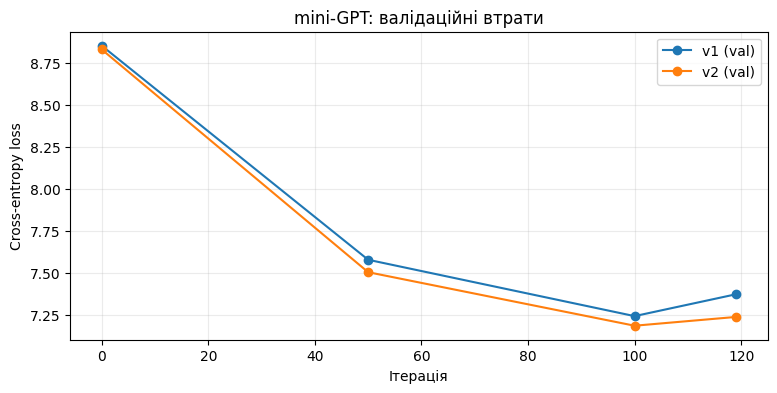

,Модель,Val loss,Найкраща ітерація,Остання ітерація,Згенерований текст
0,v1,7.241348,100,119,"Маю досвід роботи з \r.-) для,\r\n,.\r на,\r\n..."
1,v2,7.184263,100,119,"Маю досвід роботи з, за та...\n, з досвід. за\..."


In [13]:
plt.figure(figsize=(9, 4))
for v in variants:
    h = v["history"]
    plt.plot(h["iteration"], h["val_loss"], marker="o", label=f"{v['name']} (val)")
plt.xlabel("Ітерація")
plt.ylabel("Cross-entropy loss")
plt.title("mini-GPT: валідаційні втрати")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

PROMPT = "Маю досвід роботи з"
texts_generated = {}
for v in variants:
    model = MiniGPT(VOCAB_SIZE, embed_dim=EMBED_DIM, n_heads=N_HEADS,
                    n_layers=v["layers"], context_len=CONTEXT_LEN).to(device)
    state = torch.load(v["checkpoint"], map_location=device, weights_only=True)
    model.load_state_dict(state)
    prompt_ids = gpt_tokenizer.encode(PROMPT).ids
    assert len(prompt_ids) > 0
    ids = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    generated = model.generate(ids, new_tokens=70, temperature=0.8, top_k=35)
    texts_generated[v["name"]] = gpt_tokenizer.decode(generated[0].tolist())
    del model, state, ids, generated
    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()

display(pd.DataFrame([
    {
        "Модель": v["name"],
        "Val loss": v["val_loss"],
        "Найкраща ітерація": v["best_iter"],
        "Остання ітерація": v["last_iter"],
        "Згенерований текст": texts_generated[v["name"]],
    }
    for v in variants
]))


### 3.6. Частота оцінювання

Порівнюю `EVAL_INTERVAL=250` і `EVAL_INTERVAL=50` на двох коротких запусках з однаковою архітектурою, кількістю ітерацій та початковим станом генератора випадкових чисел.

,Інтервал,Точок,"Час, с"
0,250,3,35.45
1,50,7,36.62


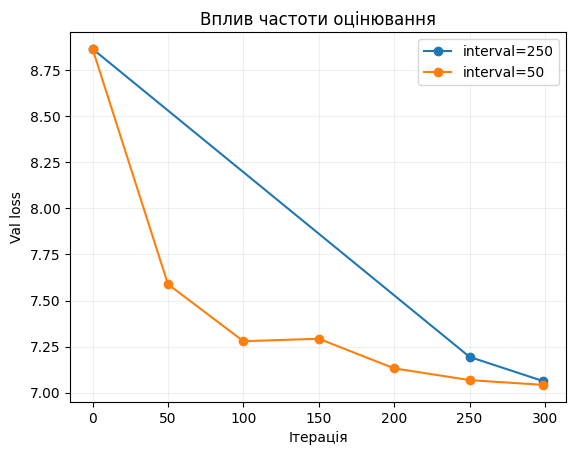

In [14]:
pilot_a = train_variant("pilot_interval250", n_layers=2, max_iters=300,
                        eval_interval=250, eval_iters=6, persist=False)
pilot_b = train_variant("pilot_interval50", n_layers=2, max_iters=300,
                        eval_interval=50, eval_iters=6, persist=False)

pilot_table = pd.DataFrame([
    {"Інтервал": 250, "Точок": len(pilot_a["history"]), "Час, с": round(pilot_a["time_sec"], 2)},
    {"Інтервал": 50, "Точок": len(pilot_b["history"]), "Час, с": round(pilot_b["time_sec"], 2)},
])
display(pilot_table)
for pilot, interval in [(pilot_a, 250), (pilot_b, 50)]:
    plt.plot(pilot["history"]["iteration"], pilot["history"]["val_loss"], marker="o", label=f"interval={interval}")
plt.title("Вплив частоти оцінювання")
plt.xlabel("Ітерація")
plt.ylabel("Val loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

del pilot_a, pilot_b


## Завдання 4. Тестування готових NLP-моделей

Перевірив шість задач через `pipeline()` на українських прикладах: аналіз тональності, класифікацію, генерацію тексту, заповнення пропуску, розпізнавання сутностей і відповіді за таблицею.

In [15]:
from transformers import pipeline

def clean_pipeline(pipe):
    del pipe
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1

sentiment = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment", device=PIPE_DEVICE)
sentences_ua = [
    "Мені дуже сподобалася співбесіда, команда була привітною.",
    "Процес найму був жахливим і неввічливим.",
]
display(pd.DataFrame([
    {"Текст": text, **res}
    for text, res in zip(sentences_ua, sentiment(sentences_ua, truncation=True))
]))
clean_pipeline(sentiment)
del sentiment


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cpu
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


,Текст,label,score
0,"Мені дуже сподобалася співбесіда, команда була...",positive,0.888276
1,Процес найму був жахливим і неввічливим.,negative,0.918766


In [16]:
zero = pipeline("zero-shot-classification", model="MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli", device=PIPE_DEVICE)
example = "Розробляю серверні API на Python та оптимізую SQL-запити."
result = zero(example, candidate_labels=["програмування", "дизайн", "маркетинг"],
              hypothesis_template="Цей текст стосується {}.")
display(pd.DataFrame({"Категорія": result["labels"], "Оцінка": result["scores"]}))
clean_pipeline(zero)
del zero


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/428M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/565 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Device set to use cpu


,Категорія,Оцінка
0,програмування,0.827308
1,дизайн,0.154030
2,маркетинг,0.018662


In [17]:
from transformers import AutoModelForCausalLM, AutoTokenizer
GEN_MODEL_ID = "Qwen/Qwen3-0.6B"
textgen = pipeline("text-generation", model=GEN_MODEL_ID, device=PIPE_DEVICE,
                   model_kwargs={"torch_dtype": torch.float16} if torch.cuda.is_available() else {})
messages = [{"role": "user", "content": "Українською напиши два короткі речення про переваги вивчення Python."}]

prompt_ua = textgen.tokenizer.apply_chat_template(messages, tokenize=False,
                            add_generation_prompt=True, enable_thinking=False)
tg = textgen(prompt_ua, max_new_tokens=90, do_sample=True, temperature=0.7, top_p=0.8,
             return_full_text=False)
display(Markdown(tg[0]["generated_text"]))
clean_pipeline(textgen)
del textgen, tg


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Device set to use cpu


1. Python є заслугованим языком, який дозволяє вивчення математики, фізики, інформатики та економіки у відповідних темах.  
2. Його простір для розробки діалектів і діалектних змін,

In [18]:
fill = pipeline("fill-mask", model="ukr-models/xlm-roberta-base-uk", device=PIPE_DEVICE)
masked = "Досвідчений розробник пише <mask> на Python."
display(pd.DataFrame([
    {"Токен": x["token_str"], "Оцінка": x["score"]}
    for x in fill(masked, top_k=3)
]))
clean_pipeline(fill)
del fill


config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/854k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Device set to use cpu


,Токен,Оцінка
0,програм,0.207497
1,PHP,0.167979
2,Python,0.155616


In [19]:
ner = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="simple", device=PIPE_DEVICE)
text_ner = "Олена Петренко працює у компанії SoftServe у Львові."
display(pd.DataFrame([
    {"Слово": x["word"], "Тип": x["entity_group"]}
    for x in ner(text_ner)
]))
clean_pipeline(ner)
del ner


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/854k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Device set to use cpu
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


,Слово,Тип
0,О,PER
1,лена Петренко,PER
2,Soft,ORG
3,Ser,ORG
4,ve,ORG
5,Львові,LOC


In [20]:
qa_table = pipeline("table-question-answering", model="google/tapas-small-finetuned-wikisql-supervised", device=PIPE_DEVICE)
table_ua = {
    "Спеціальність": ["Програмування", "Дизайн", "Маркетинг"],
    "Кандидатів": ["12", "8", "6"],
    "Місто": ["Житомир", "Львів", "Київ"],
}
display(pd.DataFrame([
    qa_table(table=table_ua, query="Скільки кандидатів у програмуванні?")
]))
clean_pipeline(qa_table)
del qa_table


config.json: 0.00B [00:00, ?B/s]

TAPAS models are not usable since `tensorflow_probability` can't be loaded. It seems you have `tensorflow_probability` installed with the wrong tensorflow version. Please try to reinstall it following the instructions here: https://github.com/tensorflow/probability.


pytorch_model.bin:   0%|          | 0.00/117M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/117M [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

Device set to use cpu
/usr/local/lib/python3.13/dist-packages/transformers/models/tapas/tokenization_tapas.py:2700: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  text = normalize_for_match(row[col_index].text)
/usr/local/lib/python3.13/dist-packages/transformers/models/tapas/tokenization_tapas.py:1494: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cell = row[col_index]


,answer,coordinates,cells,aggregator
0,,[],[],NONE


### 4.7. Temperature, top-p та thinking

Перевіряю, як змінюється генерація Qwen3 при різних `temperature` і `top_p`. Окремо порівнюю відповіді з `enable_thinking=False` та `enable_thinking=True`.

In [21]:
hf_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL_ID)
hf_model = AutoModelForCausalLM.from_pretrained(
    GEN_MODEL_ID, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
).to(device).eval()

@torch.inference_mode()
def sample_qwen(prompt, temperature, top_p, enable_thinking=False, max_new_tokens=130):
    chat = hf_tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=False,
        add_generation_prompt=True, enable_thinking=enable_thinking,
    )
    inputs = hf_tokenizer(chat, return_tensors="pt").to(device)
    generated = hf_model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=True,
        temperature=temperature, top_p=top_p,
        pad_token_id=hf_tokenizer.eos_token_id,
    )
    tokens = generated[0][inputs["input_ids"].shape[1]:]
    return hf_tokenizer.decode(tokens, skip_special_tokens=False)

SAMPLE_PROMPT = "Продовж українською коротку історію: На першій роботі молодий програміст"
generation_results = []
for temp, top_p in [(0.2, 0.8), (0.8, 0.8), (1.4, 0.8), (0.8, 0.95)]:
    generation_results.append({
        "Temperature": temp,
        "Top-p": top_p,
        "Текст": sample_qwen(SAMPLE_PROMPT, temp, top_p, max_new_tokens=90),
    })
display(pd.DataFrame(generation_results))

answer_off = sample_qwen("Поясни коротко, навіщо тестувати код.", 0.7, 0.9, False, 140)
answer_on = sample_qwen("Поясни коротко, навіщо тестувати код.", 0.7, 0.9, True, 210)
display(pd.DataFrame({
    "Режим": ["Thinking OFF", "Thinking ON"],
    "Текст": [answer_off, answer_on],
}))
del hf_model, hf_tokenizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


`torch_dtype` is deprecated! Use `dtype` instead!


,Temperature,Top-p,Текст
0,0.2,0.80,На першій роботі молодий програміст виконав ун...
1,0.8,0.80,"На першій роботі молодий програміст, що він зд..."
2,1.4,0.80,На першій роботі молодий програміст зустрілся ...
3,0.8,0.95,На першій роботі молодий програміст використав...


,Режим,Текст
0,Thinking OFF,Коротко: \nТестування коду допомагає застосув...
1,Thinking ON,"<think>\nOkay, the user is asking why to test ..."


## Завдання 5. Порівняння двох моделей

### 5.1. Дані для класифікації

Для задачі `zero-shot-classification` підготував 18 українських речень із трьома категоріями: програмування, дизайн і маркетинг. Для оцінювання використовую `accuracy`.

In [22]:
import evaluate

LABELED_TEXTS = [
    ("Розробив REST API на Python з авторизацією та тестами.", "програмування"),
    ("Підтримував вебсервери і виправляв помилки в JavaScript.", "програмування"),
    ("Писала SQL-запити й створювала міграції бази даних.", "програмування"),
    ("Працював над мобільним застосунком на Kotlin.", "програмування"),
    ("Оптимізувала алгоритми обробки даних у Python.", "програмування"),
    ("Розробляю автоматизовані тести та CI-пайплайни.", "програмування"),
    ("Створювала іконки та макети сайтів у Figma.", "дизайн"),
    ("Розробляв візуальний стиль бренду і логотипи.", "дизайн"),
    ("Підготувала дизайн інтерфейсу мобільного застосунку.", "дизайн"),
    ("Малюю ілюстрації для вебсайтів та друкованої реклами.", "дизайн"),
    ("Верстав графічні макети й готував композиції для афіш.", "дизайн"),
    ("Проєктувала прототипи сторінок з урахуванням UX.", "дизайн"),
    ("Налаштовував рекламу у соціальних мережах та аналізував CTR.", "маркетинг"),
    ("Проводила рекламні кампанії та досліджувала аудиторію.", "маркетинг"),
    ("Створюю контент-план і маркетингову стратегію бренду.", "маркетинг"),
    ("Оптимізував воронку продажів і просування продукту.", "маркетинг"),
    ("Відстежувала конверсії рекламних оголошень.", "маркетинг"),
    ("Планував email-розсилки та просування у пошукових системах.", "маркетинг"),
]
CANDIDATE_LABELS = ["програмування", "дизайн", "маркетинг"]
EVAL_TEXTS = [text for text, _ in LABELED_TEXTS]
Y_TRUE = [CANDIDATE_LABELS.index(label) for _, label in LABELED_TEXTS]
assert len(LABELED_TEXTS) == 18
accuracy = evaluate.load("accuracy")
display(pd.DataFrame(LABELED_TEXTS, columns=["Речення", "Правильна мітка"]).head(6))


,Речення,Правильна мітка
0,Розробив REST API на Python з авторизацією та ...,програмування
1,Підтримував вебсервери і виправляв помилки в J...,програмування
2,Писала SQL-запити й створювала міграції бази д...,програмування
3,Працював над мобільним застосунком на Kotlin.,програмування
4,Оптимізувала алгоритми обробки даних у Python.,програмування
5,Розробляю автоматизовані тести та CI-пайплайни.,програмування


### 5.2. Точність, час і кількість параметрів

Порівнюю `multilingual-MiniLMv2` та `mDeBERTa-v3-base` за `accuracy`, часом обробки й кількістю параметрів.

In [23]:
MODEL_IDS = [
    "MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli",
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
]
DEFAULT_TEMPLATE = "Цей текст стосується {}."

def evaluate_zero_shot(model_id, template):
    pipe = pipeline("zero-shot-classification", model=model_id, device=PIPE_DEVICE)
    parameter_count = sum(p.numel() for p in pipe.model.parameters())
    if torch.cuda.is_available(): torch.cuda.synchronize()
    begin = time.perf_counter()
    predictions = []
    for phrase in EVAL_TEXTS:
        pred = pipe(
            phrase, candidate_labels=CANDIDATE_LABELS,
            hypothesis_template=template, multi_label=False,
        )
        predictions.append(CANDIDATE_LABELS.index(pred["labels"][0]))
    if torch.cuda.is_available(): torch.cuda.synchronize()
    elapsed = time.perf_counter() - begin
    acc = accuracy.compute(predictions=predictions, references=Y_TRUE)["accuracy"]
    del pipe
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return {"section": "zero-shot", "model": model_id, "setting": template,
            "metric": "accuracy", "value": acc, "parameters": parameter_count,
            "seconds": elapsed, "seconds_per_text": elapsed / len(EVAL_TEXTS)}

base_scores = [evaluate_zero_shot(mid, DEFAULT_TEMPLATE) for mid in MODEL_IDS]
RESULTS.extend(base_scores)
display(pd.DataFrame(base_scores)[["model", "value", "seconds", "seconds_per_text", "parameters"]])
pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)


Device set to use cpu


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.3M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Device set to use cpu


,model,value,seconds,seconds_per_text,parameters
0,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,0.611111,1.850703,0.102817,106995075
1,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,0.944444,125.070025,6.948335,278811651


### 5.3. Перевірка налаштувань

Для моделі з кращою точністю змінюю `hypothesis_template` трьома способами.

In [24]:
base_best = max(base_scores, key=lambda row: row["value"])
BEST_BASE_MODEL = base_best["model"]
TEMPLATE_VARIANTS = [
    "Основна тема тексту: {}.",
    "Текст описує роботу у сфері {}.",
    "Професійний напрям цього профілю: {}.",
]
for template in TEMPLATE_VARIANTS:
    RESULTS.append(evaluate_zero_shot(BEST_BASE_MODEL, template))

results_df = pd.DataFrame(RESULTS)
results_df.to_csv(RESULTS_CSV, index=False)
zero_results = results_df[results_df["section"] == "zero-shot"].sort_values("value", ascending=False)
display(zero_results[["model", "setting", "value", "seconds", "parameters"]])
best_zero = zero_results.iloc[0]
BEST_MODEL = str(best_zero["model"])
BEST_TEMPLATE = str(best_zero["setting"])
first_two = pd.DataFrame(base_scores).sort_values("value", ascending=False)
model_gap = abs(float(first_two.iloc[0]["value"]) - float(first_two.iloc[1]["value"]))
setting_gap = max(x["value"] for x in RESULTS if x["section"] == "zero-shot" and x["model"] == BEST_BASE_MODEL) - min(x["value"] for x in RESULTS if x["section"] == "zero-shot" and x["model"] == BEST_BASE_MODEL)
display(pd.DataFrame([{
    "Найкраща модель": BEST_MODEL,
    "Шаблон": BEST_TEMPLATE,
    "Accuracy": float(best_zero["value"]),
    "Різниця між моделями": model_gap,
    "Різниця між шаблонами": setting_gap,
}]))


Device set to use cpu
Device set to use cpu
Device set to use cpu


,model,setting,value,seconds,parameters
4,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Основна тема тексту: {}.,1.000000,125.163542,278811651
5,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Текст описує роботу у сфері {}.,0.944444,133.422697,278811651
3,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Цей текст стосується {}.,0.944444,125.070025,278811651
6,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Професійний напрям цього профілю: {}.,0.944444,131.836844,278811651
2,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,Цей текст стосується {}.,0.611111,1.850703,106995075


,Найкраща модель,Шаблон,Accuracy,Різниця між моделями,Різниця між шаблонами
0,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Основна тема тексту: {}.,1.0,0.333333,0.055556


## Завдання 6. Gradio-застосунок

Створив `CV-навігатор`, який за коротким українським описом досвіду визначає найближчу категорію: програмування, дизайн або маркетинг.

In [27]:
import gradio as gr

app_classifier = pipeline("zero-shot-classification", model=BEST_MODEL, device=PIPE_DEVICE)

def classify_cv(text):
    text = (text or "").strip()
    if len(text) < 15:
        return {}, "Введіть принаймні 15 символів опису професійного досвіду."
    result = app_classifier(
        text[:3000], candidate_labels=CANDIDATE_LABELS,
        hypothesis_template=BEST_TEMPLATE, multi_label=False,
    )
    probabilities = dict(zip(result["labels"], map(float, result["scores"])))
    return probabilities, f"Найімовірніший напрям: {result['labels'][0]}. Це тематична підказка, а не кадровий висновок."

with gr.Blocks(title="CV-навігатор") as app:
    gr.Markdown("# CV-навігатор\nВизначення тематичного напряму українськомовного професійного опису.")
    cv_input = gr.Textbox(label="Короткий опис досвіду", lines=6,
        placeholder="Наприклад: Пишу код на Python, створюю API та налаштовую бази даних.")
    analyze = gr.Button("Визначити напрям")
    chart = gr.Label(label="Розподіл ймовірностей", num_top_classes=3)
    explanation = gr.Textbox(label="Пояснення", interactive=False)
    analyze.click(classify_cv, inputs=cv_input, outputs=[chart, explanation])
    gr.Examples(
        examples=[
            ["Створюю інтерфейси у Figma, розробляю логотипи і дизайн-системи."],
            ["Пишу бекенд на Python, тестую API та оптимізую SQL."],
            ["Запускаю рекламні кампанії, аналізую CTR та конверсії."],
        ],
        inputs=cv_input,
    )

app.launch(share=True, debug=True, show_error=True, inline=False)


Device set to use cpu


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://386392f5e8a9da7f6b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://386392f5e8a9da7f6b.gradio.live


In [26]:
files_expected = [MODELS_DIR / "minigpt_v1.pt", MODELS_DIR / "minigpt_v2.pt", RESULTS_CSV]
files_expected.append(RUNS_DIR)
display(pd.DataFrame([
    {"Файл або папка": str(path.relative_to(ROOT)), "Існує": path.exists()}
    for path in files_expected
]))
display(pd.read_csv(RESULTS_CSV))


,Файл або папка,Існує
0,models/minigpt_v1.pt,True
1,models/minigpt_v2.pt,True
2,results.csv,True
3,runs,True


,section,model,setting,metric,value,parameters,seconds,seconds_per_text
0,miniGPT,v1,layers=2,val_loss,7.241348,1946224,14.506844,NaN
1,miniGPT,v2,layers=4,val_loss,7.184263,2342000,20.782974,NaN
2,zero-shot,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,Цей текст стосується {}.,accuracy,0.611111,106995075,1.850703,0.102817
3,zero-shot,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Цей текст стосується {}.,accuracy,0.944444,278811651,125.070025,6.948335
4,zero-shot,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Основна тема тексту: {}.,accuracy,1.000000,278811651,125.163542,6.953530
5,zero-shot,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Текст описує роботу у сфері {}.,accuracy,0.944444,278811651,133.422697,7.412372
6,zero-shot,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,Професійний напрям цього профілю: {}.,accuracy,0.944444,278811651,131.836844,7.324269
